# FER2013 — CNN tự thiết kế, hợp nhất đặc trưng ở hai tầng

Notebook chạy độc lập trên Kaggle. Model được viết từ các lớp Conv2d,
BatchNorm, ReLU và residual block; **không gọi backbone torchvision.models,
không dùng pretrained weights, không có Transformer**. Toàn bộ trọng số học
từ đầu trên FER2013. Đây là một thiết kế CNN cho dự án, không tuyên bố các
khối residual hoặc attention là ý tưởng nghiên cứu mới.

Mặc định dùng ảnh xám **1 × 48 × 48**, 4 stage với số kênh **32, 64, 128, 192**,
mỗi stage gồm 2 residual block. Lấy đặc trưng ở Stage 3 và Stage 4, pooling
rồi ghép thành vector 256 chiều. Tổng **1.947.751 tham số** với cấu hình mặc định.

## Chạy trên Kaggle

1. Import notebook và gắn dataset FER-2013 của `msambare` có `train/`, `test/`.
2. Bật GPU trong Settings → Accelerator, chọn T4 hoặc GPU khả dụng.
3. Giữ `EXPERIMENT='fusion'` cho lần thử đầu; chạy từ trên xuống.
4. Xem validation accuracy, Macro F1 và clean train accuracy. Sau khi chốt
   cấu hình, chạy cell test để có report và confusion matrix.
5. Tải file `custom_cnn_fer2013_best_checkpoint.pth` trong thư mục `Output:`.

Không cần bật Internet để tải weights hay clone repo. Notebook dùng các
thư viện có sẵn trong môi trường Kaggle, không cài hoặc nâng cấp PyTorch.
Chưa có accuracy thực nghiệm cho thiết kế này; kết quả train từ đầu có thể
thấp hơn hoặc cao hơn model pretrained trước, cần kiểm chứng.

In [2]:
import json
import math
import os
import random
import sys
from time import perf_counter
from concurrent.futures import ThreadPoolExecutor
from contextlib import closing, nullcontext
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from tqdm.auto import tqdm

CLASS_NAMES = ('angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise')
NORMALIZE_MEAN = (0.5,)
NORMALIZE_STD = (0.5,)
print(f'Python {sys.version.split()[0]} | torch {torch.__version__} | torchvision {torchvision.__version__}')

Python 3.13.16 | torch 2.11.0+cu130 | torchvision 0.26.0+cu130


## 1. Cấu hình và thí nghiệm đối chứng

Notebook chỉ train **một preset mỗi run**, không tự chạy cả ba:

| Preset | Đặc trưng phân loại | Mục tiêu |
|---|---|---|
| `deep_only` | Stage 4 → Average Pooling → Linear | Đối chứng CNN một nhánh |
| `fusion` (mặc định) | Stage 3 + Stage 4 → pooling → ghép → Linear | Kiểm tra hợp nhất hai tầng |
| `fusion_cbam` | Stage 3 + Stage 4 có CBAM | Kiểm tra đóng góp thêm của attention |

Các preset dùng cùng lịch train, augmentation và split. `split_seed=42` giữ
tập validation và 2.048 ảnh clean train cố định; `seed` điều khiển huấn luyện.
Mặc định 50 epoch để có cùng ngân sách epoch với các run trước. Train từ đầu
dùng AdamW LR **1e-3 cho toàn mạng**, không dùng learning rate fine-tune 1e-5.
Có warmup 5 epoch rồi cosine về 1% LR gốc.

Đầu vào là một kênh, chuẩn hóa cố định `(x - 0.5) / 0.5` về khoảng [-1, 1].
Đây là lựa chọn cấu hình, không phải mean/std ước lượng từ test. Thay đổi cả
pretrained, kích thước đầu vào và kiến trúc so với CCT là so sánh hai hệ thống;
các preset trong notebook này mới là đối chứng để tách tác dụng từng nhánh.

Mặc định `multi_gpu=False` vì model nhỏ; có thể bật để dùng cả hai T4.
Batch size 64 là tổng cả hai GPU. DataParallel có chi phí đồng bộ và thay đổi
thống kê BatchNorm theo từng phần batch; cần đo tốc độ và không kỳ vọng kết
quả giống tuyệt đối một GPU. `num_workers=0` tránh lỗi multiprocessing trong
notebook, `cache_workers=4` chỉ dùng luồng I/O để đọc cache ảnh gốc.

In [3]:
EXPERIMENT = 'fusion'
EXPERIMENT_PRESETS = {
    'deep_only': {'fusion': False, 'use_cbam': False},
    'fusion': {'fusion': True, 'use_cbam': False},
    'fusion_cbam': {'fusion': True, 'use_cbam': True},
}

CFG = {
    'experiment': EXPERIMENT,
    'run_name': f'fer2013_custom_cnn_{EXPERIMENT}',
    'data_dir': None,
    'output_root': '/kaggle/working' if Path('/kaggle').is_dir() else 'outputs/custom_cnn',
    'seed': 42,
    'split_seed': 42,
    'validation_fraction': 0.10,
    'image_size': 48,
    'batch_size': 64,
    'epochs': 50,
    'device': 'cuda' if Path('/kaggle').is_dir() else 'auto',
    'multi_gpu': False,
    'max_gpus': 2,
    'cpu_threads': 2,
    'num_workers': 0,
    'cache_images': True,
    'cache_workers': 4,
    'cache_max_mib': 256,
    'benchmark_batches': 3,
    'stage_channels': (32, 64, 128, 192),
    'blocks_per_stage': 2,
    'fusion_channels': 64,
    'fusion': True,
    'use_cbam': False,
    'cbam_reduction': 16,
    'cbam_spatial_kernel': 7,
    'dropout': 0.30,
    'lr': 1e-3,
    'weight_decay': 3e-4,
    'warmup_epochs': 5,
    'min_lr_ratio': 0.01,
    'label_smoothing': 0.05,
    'mixup_alpha': 0.10,
    'mixup_probability': 0.30,
    'erasing_p': 0.10,
    'gradient_clip': 1.0,
    'use_amp': True,
    'clean_train_every': 5,
    'clean_train_max_samples': 2048,
}
if EXPERIMENT not in EXPERIMENT_PRESETS:
    raise ValueError(f'Preset không hợp lệ: {EXPERIMENT}')
CFG.update(EXPERIMENT_PRESETS[EXPERIMENT])
# Tùy chỉnh cho một run đặt sau dòng CFG.update trên, ví dụ CFG.update(seed=43).


def validate_config(cfg):
    if cfg['image_size'] != 48:
        raise ValueError('Notebook này dùng đầu vào 48 x 48, một kênh.')
    if len(cfg['stage_channels']) != 4 or any(
        isinstance(c, bool) or not isinstance(c, int) or c < 1 for c in cfg['stage_channels']
    ):
        raise ValueError('Cần 4 số kênh nguyên dương.')
    for key in ('batch_size', 'epochs', 'blocks_per_stage', 'fusion_channels', 'cpu_threads',
                'max_gpus', 'cache_workers', 'benchmark_batches', 'clean_train_every',
                'clean_train_max_samples', 'cbam_reduction'):
        if isinstance(cfg[key], bool) or not isinstance(cfg[key], int) or cfg[key] < 1:
            raise ValueError(f'{key} phải là số nguyên dương.')
    if cfg['batch_size'] < 2 or cfg['clean_train_max_samples'] < len(CLASS_NAMES):
        raise ValueError('Cần batch_size>=2 và clean_train_max_samples>=7.')
    if not isinstance(cfg['num_workers'], int) or cfg['num_workers'] < 0:
        raise ValueError('num_workers phải là số nguyên không âm.')
    if not 0 <= cfg['warmup_epochs'] < cfg['epochs']:
        raise ValueError('warmup_epochs phải từ 0 đến epochs-1.')
    if not 0 < cfg['validation_fraction'] < 1:
        raise ValueError('validation_fraction phải nằm trong (0, 1).')
    for key in ('fusion', 'use_cbam', 'multi_gpu', 'use_amp', 'cache_images'):
        if not isinstance(cfg[key], bool):
            raise ValueError(f'{key} phải là bool.')
    if cfg['use_cbam'] and not cfg['fusion']:
        raise ValueError('Preset attention của notebook cần fusion=True.')
    if cfg['cbam_spatial_kernel'] not in (3, 7):
        raise ValueError('cbam_spatial_kernel phải là 3 hoặc 7.')
    if cfg['device'] not in ('auto', 'cpu', 'cuda'):
        raise ValueError('device phải là auto, cpu hoặc cuda.')
    for key in ('seed', 'split_seed'):
        if not isinstance(cfg[key], int) or not 0 <= cfg[key] < 2**32:
            raise ValueError(f'{key} phải là số nguyên trong [0, 2**32).')
    for key in ('dropout', 'label_smoothing'):
        if not 0 <= cfg[key] < 1:
            raise ValueError(f'{key} phải trong [0, 1).')
    for key in ('erasing_p', 'mixup_probability', 'min_lr_ratio'):
        if not 0 <= cfg[key] <= 1:
            raise ValueError(f'{key} phải trong [0, 1].')
    if cfg['lr'] <= 0 or cfg['weight_decay'] < 0 or cfg['mixup_alpha'] < 0:
        raise ValueError('Learning rate, weight decay hoặc mixup_alpha không hợp lệ.')
    if cfg['gradient_clip'] <= 0 or cfg['cache_max_mib'] <= 0:
        raise ValueError('gradient_clip và cache_max_mib phải dương.')


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def resolve_runtime_device(cfg):
    if cfg['device'] == 'cuda' and not torch.cuda.is_available():
        raise RuntimeError('CUDA chưa khả dụng. Bật GPU trên Kaggle hoặc đặt device=cpu khi chạy local.')
    name = cfg['device']
    if name == 'auto':
        name = 'cuda' if torch.cuda.is_available() else 'cpu'
    return torch.device('cuda:0' if name == 'cuda' else name)


validate_config(CFG)
torch.set_num_threads(CFG['cpu_threads'])
DEVICE = resolve_runtime_device(CFG)
print('Selected device:', DEVICE, '| CPU threads:', torch.get_num_threads())
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(DEVICE), '| Visible GPUs:', torch.cuda.device_count())
print(json.dumps(CFG, indent=2, ensure_ascii=False))

Selected device: cuda:0 | CPU threads: 2
GPU: Tesla T4 | Visible GPUs: 2
{
  "experiment": "fusion",
  "run_name": "fer2013_custom_cnn_fusion",
  "data_dir": null,
  "output_root": "/kaggle/working",
  "seed": 42,
  "split_seed": 42,
  "validation_fraction": 0.1,
  "image_size": 48,
  "batch_size": 64,
  "epochs": 50,
  "device": "cuda",
  "multi_gpu": false,
  "max_gpus": 2,
  "cpu_threads": 2,
  "num_workers": 0,
  "cache_images": true,
  "cache_workers": 4,
  "cache_max_mib": 256,
  "benchmark_batches": 3,
  "stage_channels": [
    32,
    64,
    128,
    192
  ],
  "blocks_per_stage": 2,
  "fusion_channels": 64,
  "fusion": true,
  "use_cbam": false,
  "cbam_reduction": 16,
  "cbam_spatial_kernel": 7,
  "dropout": 0.3,
  "lr": 0.001,
  "weight_decay": 0.0003,
  "warmup_epochs": 5,
  "min_lr_ratio": 0.01,
  "label_smoothing": 0.05,
  "mixup_alpha": 0.1,
  "mixup_probability": 0.3,
  "erasing_p": 0.1,
  "gradient_clip": 1.0,
  "use_amp": true,
  "clean_train_every": 5,
  "clean_trai

## 2. Dữ liệu và split cố định

Dataset chỉ có `train/` và `test/`: tách 10% **train** theo lớp với seed 42
làm validation. Với cùng các file, split này khớp notebook CCT trước:
25.838 train, 2.871 validation. Nếu có `val/`, dùng tập đó.
Test chỉ được mở trong cell đánh giá cuối, không tham gia chọn checkpoint.

Cache lưu ảnh gốc một lần, không lưu augmentation. Mỗi lần lấy ảnh train
vẫn lật/xoay/erasing ngẫu nhiên; validation và clean train chỉ resize,
grayscale một kênh, ToTensor và Normalize. Chỉ số clean train dùng một mẫu
cố định nằm trong tập train, không phải một tập kiểm tra độc lập mới.

In [4]:
def find_data_root(configured_path=None):
    if configured_path:
        root = Path(configured_path).expanduser().resolve()
        if not (root / 'train').is_dir():
            raise FileNotFoundError(f'Không tìm thấy train/ trong {root}')
        return root
    preferred = [
        Path('/kaggle/input/datasets/msambare/fer2013'),
        Path('/kaggle/input/fer2013'),
        Path('data/fer2013'),
    ]
    for root in preferred:
        if (root / 'train' / 'angry').is_dir():
            return root.resolve()
    input_root = Path('/kaggle/input')
    candidates = set()
    for pattern in ('*/train', '*/*/train', '*/*/*/train'):
        for train_path in input_root.glob(pattern):
            if (train_path / 'angry').is_dir():
                candidates.add(train_path.parent.resolve())
    if len(candidates) == 1:
        return candidates.pop()
    raise FileNotFoundError(
        f'Hãy gắn dataset FER2013 và đặt CFG[data_dir]. Tìm thấy: {sorted(map(str, candidates))}'
    )


def build_transforms(cfg, training=False):
    operations = [
        transforms.Resize((cfg['image_size'], cfg['image_size'])),
        transforms.Grayscale(num_output_channels=1),
    ]
    if training:
        operations += [transforms.RandomHorizontalFlip(), transforms.RandomRotation(10)]
    operations += [
        transforms.ToTensor(),
        transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
    ]
    if training:
        operations.append(transforms.RandomErasing(
            p=cfg['erasing_p'], scale=(0.02, 0.10), ratio=(0.3, 3.3), value=0,
        ))
    return transforms.Compose(operations)


def check_classes(dataset):
    if dataset.classes != list(CLASS_NAMES):
        raise ValueError(f'Cần các lớp {CLASS_NAMES}, tìm thấy {dataset.classes}')


def iter_decoded_images(paths, workers):
    """Đọc song song theo nhóm nhỏ, giữ nguyên thứ tự và giới hạn ảnh chờ trong RAM."""
    if workers == 1:
        for path in paths:
            yield path, datasets.folder.default_loader(path)
        return
    with ThreadPoolExecutor(max_workers=workers) as pool:
        # Không submit toàn bộ dataset để tránh tích lũy hàng chục nghìn kết quả.
        chunk_size = workers * 2
        for start in range(0, len(paths), chunk_size):
            chunk = paths[start:start + chunk_size]
            for path, image in zip(chunk, pool.map(datasets.folder.default_loader, chunk)):
                yield path, image


class CachedImageLoader:
    """Cache ảnh RGB gốc; dùng luồng I/O, không tạo tiến trình DataLoader con."""

    def __init__(self, paths, max_mib, workers=4):
        self.images = {}
        self.used_bytes = 0
        budget = int(max_mib * 1024 ** 2)
        paths = list(dict.fromkeys(map(str, paths)))
        print(f'Reading {len(paths):,} images with {workers} I/O threads; cache is reused across epochs.')
        with closing(iter_decoded_images(paths, workers)) as decoded, tqdm(
            total=len(paths), desc='Cache decoded images', unit='img',
        ) as progress:
            for path, image in decoded:
                size = image.width * image.height * len(image.getbands())
                if self.used_bytes + size > budget:
                    image.close()
                    break
                self.images[path] = image
                self.used_bytes += size
                progress.update(1)
        print(f'Cached {len(self.images):,} images | RGB pixels {self.used_bytes / 1024**2:.1f} MiB')
        print('Giới hạn trên tính theo pixel RGB; đối tượng PIL/Python dùng thêm một phần RAM.')

    def __call__(self, path):
        path = str(path)
        image = self.images.get(path)
        return image.copy() if image is not None else datasets.folder.default_loader(path)


def attach_image_cache(cfg, *image_datasets):
    if not cfg['cache_images']:
        return None
    paths = (path for dataset in image_datasets for path, _ in dataset.samples)
    cache = CachedImageLoader(paths, cfg['cache_max_mib'], workers=cfg['cache_workers'])
    for dataset in image_datasets:
        dataset.loader = cache
    return cache


def build_data(cfg, root, device):
    root = Path(root).resolve()
    augmented = datasets.ImageFolder(root / 'train', transform=build_transforms(cfg, True))
    clean = datasets.ImageFolder(root / 'train', transform=build_transforms(cfg))
    check_classes(augmented)
    indices = np.arange(len(augmented))
    if (root / 'val').is_dir():
        validation_data = datasets.ImageFolder(root / 'val', transform=build_transforms(cfg))
        check_classes(validation_data)
        train_indices, val_indices = indices, np.arange(len(validation_data))
        validation_source = 'val/'
    else:
        train_indices, val_indices = train_test_split(
            indices, test_size=cfg['validation_fraction'],
            random_state=cfg['split_seed'], stratify=augmented.targets,
        )
        validation_data = clean
        validation_source = 'stratified split from train/'
    attach_image_cache(cfg, augmented, clean, validation_data)
    train_indices = sorted(map(int, train_indices))
    val_indices = sorted(map(int, val_indices))
    expected_labels = set(range(len(CLASS_NAMES)))
    if {augmented.targets[i] for i in train_indices} != expected_labels:
        raise ValueError('Train sau khi chia không đủ 7 lớp.')
    if {validation_data.targets[i] for i in val_indices} != expected_labels:
        raise ValueError('Validation sau khi chia không đủ 7 lớp; tăng kích thước split.')
    train_set = Subset(augmented, train_indices)
    val_set = Subset(validation_data, val_indices)
    train_paths = {augmented.samples[i][0] for i in train_indices}
    val_paths = {validation_data.samples[i][0] for i in val_indices}
    if train_paths & val_paths:
        raise ValueError('Train và validation có đường dẫn trùng nhau.')

    clean_indices = train_indices
    clean_limit = cfg['clean_train_max_samples']
    if clean_limit < len(train_indices):
        _, selected = train_test_split(
            train_indices, test_size=clean_limit, random_state=cfg['split_seed'],
            stratify=np.asarray(clean.targets)[train_indices],
        )
        clean_indices = sorted(map(int, selected))
    clean_set = Subset(clean, clean_indices)
    options = {
        'batch_size': cfg['batch_size'],
        'num_workers': cfg['num_workers'],
        'pin_memory': device.type == 'cuda',
        'worker_init_fn': seed_worker,
    }
    generator = torch.Generator().manual_seed(cfg['seed'])
    loaders = {
        'train': DataLoader(train_set, shuffle=True, generator=generator, **options),
        'val': DataLoader(val_set, shuffle=False, **options),
        'clean_train': DataLoader(clean_set, shuffle=False, **options),
    }
    records = []
    for split, dataset, selected in (
        ('train', augmented, train_indices), ('val', validation_data, val_indices),
    ):
        for index in selected:
            path, label = dataset.samples[index]
            records.append({'split': split, 'path': str(Path(path).relative_to(root)),
                            'label': label, 'class': CLASS_NAMES[label]})
    manifest = pd.DataFrame(records)
    summary = {'train_size': len(train_set), 'val_size': len(val_set),
               'clean_train_size': len(clean_set), 'validation_source': validation_source}
    return loaders, manifest, summary

In [5]:
seed_everything(CFG['seed'])
DATA_ROOT = find_data_root(CFG['data_dir'])
loaders, split_manifest, data_summary = build_data(CFG, DATA_ROOT, DEVICE)
print('Dataset:', DATA_ROOT)
print(json.dumps(data_summary, indent=2))
print(pd.crosstab(split_manifest['class'], split_manifest['split']).reindex(CLASS_NAMES))
print('test/ được giữ riêng; chỉ đọc ở cell đánh giá cuối.')

Reading 28,709 images with 4 I/O threads; cache is reused across epochs.


Cache decoded images:   0%|          | 0/28709 [00:00<?, ?img/s]

Cached 28,709 images | RGB pixels 189.2 MiB
Giới hạn trên tính theo pixel RGB; đối tượng PIL/Python dùng thêm một phần RAM.
Dataset: /kaggle/input/datasets/msambare/fer2013
{
  "train_size": 25838,
  "val_size": 2871,
  "clean_train_size": 2048,
  "validation_source": "stratified split from train/"
}
split     train  val
class               
angry      3596  399
disgust     392   44
fear       3687  410
happy      6493  722
neutral    4469  496
sad        4347  483
surprise   2854  317
test/ được giữ riêng; chỉ đọc ở cell đánh giá cuối.


## 3. Kiến trúc CNN

| Khối | Cấu hình mặc định | Đầu ra |
|---|---|---|
| Input | Ảnh xám | B × 1 × 48 × 48 |
| Stem | Conv 3×3, BN, ReLU | B × 32 × 48 × 48 |
| Stage 1 | 2 residual block, stride 1 | B × 32 × 48 × 48 |
| Stage 2 | 2 block, block đầu stride 2 | B × 64 × 24 × 24 |
| Stage 3 | 2 block, block đầu stride 2 | B × 128 × 12 × 12 |
| Stage 4 | 2 block, block đầu stride 2 | B × 192 × 6 × 6 |
| Nhánh Stage 3 | Conv 1×1, 128→64, Average Pooling | B × 64 |
| Nhánh Stage 4 | Average Pooling | B × 192 |
| Ghép hai nhánh | Concatenate | B × 256 |
| Classifier | Dropout 0.3 → Linear 256→7 | B × 7 logits |

Mỗi residual block có Conv 3×3 → BN → ReLU → Conv 3×3 → BN, cộng với nhánh
identity hoặc Conv 1×1 + BN khi đổi kích thước, rồi ReLU. Không giảm ảnh
ngay bằng stem 7×7/stride 2. Giả thuyết là đặc trưng ở 12×12 và 6×6 bổ sung
nhau; cần so với `deep_only` để kiểm chứng thay vì suy ra từ train accuracy.

`fusion_cbam` thêm CBAM trên Stage 4 trước pooling. Các khối CNN cốt lõi và
số stage không đổi giữa các preset; nhánh Stage 3 chỉ tồn tại khi bật fusion.

In [6]:
class ChannelAttention(nn.Module):
    def __init__(self, channels=512, reduction=16):
        super().__init__()
        if channels < 1 or not isinstance(reduction, int) or not 1 <= reduction <= channels:
            raise ValueError('Cần channels >= 1 và reduction nguyên trong [1, channels].')
        hidden = max(1, channels // reduction)
        self.shared_mlp = nn.Sequential(
            nn.Conv2d(channels, hidden, kernel_size=1, bias=False),
            nn.ReLU(),
            nn.Conv2d(hidden, channels, kernel_size=1, bias=False),
        )

    def forward(self, x):
        average = F.adaptive_avg_pool2d(x, 1)
        maximum = F.adaptive_max_pool2d(x, 1)
        weights = torch.sigmoid(self.shared_mlp(average) + self.shared_mlp(maximum))
        return x * weights


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        if kernel_size not in (3, 7):
            raise ValueError('Spatial kernel phải là 3 hoặc 7.')
        self.conv = nn.Conv2d(2, 1, kernel_size=kernel_size,
                              padding=kernel_size // 2, bias=False)

    def forward(self, x):
        average = x.mean(dim=1, keepdim=True)
        maximum = x.amax(dim=1, keepdim=True)
        weights = torch.sigmoid(self.conv(torch.cat((average, maximum), dim=1)))
        return x * weights


class CBAM(nn.Module):
    def __init__(self, channels=512, reduction=16, spatial_kernel=7):
        super().__init__()
        self.channel_attention = ChannelAttention(channels, reduction)
        self.spatial_attention = SpatialAttention(spatial_kernel)

    def forward(self, x):
        return self.spatial_attention(self.channel_attention(x))


class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
        )
        self.shortcut = nn.Identity() if stride == 1 and in_channels == out_channels else nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
            nn.BatchNorm2d(out_channels),
        )
        self.activation = nn.ReLU()

    def forward(self, x):
        return self.activation(self.body(x) + self.shortcut(x))


class CustomFERConvNet(nn.Module):
    def __init__(self, num_classes=7, stage_channels=(32, 64, 128, 192),
                 blocks_per_stage=2, fusion_channels=64, fusion=True, dropout=0.3,
                 use_cbam=False, cbam_reduction=16, cbam_spatial_kernel=7):
        super().__init__()
        if len(stage_channels) != 4 or min(stage_channels) < 1 or blocks_per_stage < 1:
            raise ValueError('Cần 4 stage có số kênh dương và ít nhất 1 block/stage.')
        if fusion_channels < 1 or not 0 <= dropout < 1:
            raise ValueError('fusion_channels hoặc dropout không hợp lệ.')
        if use_cbam and not fusion:
            raise ValueError('Preset CBAM cần fusion=True.')
        c1, c2, c3, c4 = stage_channels
        self.fusion = fusion
        self.stem = nn.Sequential(nn.Conv2d(1, c1, 3, padding=1, bias=False),
                                  nn.BatchNorm2d(c1), nn.ReLU())

        def stage(in_channels, out_channels, stride):
            return nn.Sequential(
                ResidualBlock(in_channels, out_channels, stride),
                *[ResidualBlock(out_channels, out_channels) for _ in range(blocks_per_stage - 1)],
            )

        self.stage1 = stage(c1, c1, 1)
        self.stage2 = stage(c1, c2, 2)
        self.stage3 = stage(c2, c3, 2)
        self.stage4 = stage(c3, c4, 2)
        self.cbam = CBAM(c4, cbam_reduction, cbam_spatial_kernel) if use_cbam else nn.Identity()
        if fusion:
            self.local_projection = nn.Conv2d(c3, fusion_channels, 1, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(c4 + (fusion_channels if fusion else 0), num_classes)
        self.initialize_weights()

    def initialize_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(module, nn.BatchNorm2d):
                nn.init.ones_(module.weight)
                nn.init.zeros_(module.bias)
            elif isinstance(module, nn.Linear):
                nn.init.xavier_uniform_(module.weight)
                nn.init.zeros_(module.bias)

    def forward_features(self, x):
        if x.ndim != 4 or tuple(x.shape[1:]) != (1, 48, 48):
            raise ValueError('CustomFERConvNet cần tensor B x 1 x 48 x 48.')
        x = self.stage2(self.stage1(self.stem(x)))
        stage3 = self.stage3(x)
        stage4 = self.cbam(self.stage4(stage3))
        return stage3, stage4

    def forward(self, x):
        stage3, stage4 = self.forward_features(x)
        deep_vector = stage4.mean(dim=(2, 3))
        if self.fusion:
            middle_vector = self.local_projection(stage3).mean(dim=(2, 3))
            features = torch.cat((middle_vector, deep_vector), dim=1)
        else:
            features = deep_vector
        return self.classifier(self.dropout(features))


def model_config_from_cfg(cfg):
    return {
        'model_type': 'custom_fer_cnn', 'num_classes': len(CLASS_NAMES),
        'stage_channels': list(cfg['stage_channels']), 'blocks_per_stage': cfg['blocks_per_stage'],
        'fusion_channels': cfg['fusion_channels'], 'fusion': cfg['fusion'],
        'dropout': cfg['dropout'], 'use_cbam': cfg['use_cbam'],
        'cbam_reduction': cfg['cbam_reduction'], 'cbam_spatial_kernel': cfg['cbam_spatial_kernel'],
    }


def build_model_from_spec(spec):
    if spec.get('model_type') != 'custom_fer_cnn' or spec.get('num_classes') != len(CLASS_NAMES):
        raise ValueError('Checkpoint không thuộc kiến trúc CustomFERConvNet 7 lớp.')
    return CustomFERConvNet(**{key: value for key, value in spec.items() if key != 'model_type'})


def build_model(cfg):
    return build_model_from_spec(model_config_from_cfg(cfg))


def unwrap_model(model):
    return model.module if isinstance(model, nn.DataParallel) else model


def execution_info(model, device):
    if isinstance(model, nn.DataParallel) and model.device_ids:
        return {'strategy': 'DataParallel', 'device_ids': list(model.device_ids)}
    ids = [0 if device.index is None else device.index] if device.type == 'cuda' else []
    return {'strategy': 'single', 'device_ids': ids}


def prepare_parallel_model(model, cfg, device):
    model = unwrap_model(model).to(device)
    if device.type != 'cuda':
        return model
    count = min(torch.cuda.device_count(), cfg.get('max_gpus', 2)) if cfg.get('multi_gpu', False) else 1
    if count < 2:
        if cfg.get('multi_gpu', False):
            print('Chỉ có một GPU được dùng; chạy tiếp bằng single GPU.')
        return model
    if device.index not in (None, 0):
        raise ValueError('DataParallel trong notebook này cần thiết bị chính cuda:0.')
    if cfg['batch_size'] < count:
        raise ValueError('batch_size tổng phải ít nhất bằng số GPU.')
    ids = list(range(count))
    parallel = nn.DataParallel(model, device_ids=ids, output_device=ids[0])
    print(f'DataParallel enabled: GPU IDs {ids} | global batch {cfg["batch_size"]}')
    for index in ids:
        print(f'  cuda:{index}: {torch.cuda.get_device_name(index)}')
    return parallel


def synchronize_model_devices(model, device):
    if device.type == 'cuda':
        for index in execution_info(model, device)['device_ids']:
            torch.cuda.synchronize(index)


def checkpoint_paths(cfg, run_dir):
    return (Path(run_dir) / 'custom_cnn_fer2013_best.pth',
            Path(run_dir) / 'custom_cnn_fer2013_best_checkpoint.pth')


def checkpoint_payload(model, cfg, epoch, metrics):
    return {
        'format_version': 1, 'state_dict': unwrap_model(model).state_dict(),
        'model_config': model_config_from_cfg(cfg), 'classes': list(CLASS_NAMES),
        'preprocess': {'image_size': 48, 'channels': 1,
                       'mean': list(NORMALIZE_MEAN), 'std': list(NORMALIZE_STD)},
        'epoch': int(epoch),
        'validation': {key: float(metrics[key]) for key in ('loss', 'accuracy', 'macro_f1')},
    }


def load_trained_model(checkpoint, device):
    payload = torch.load(checkpoint, map_location='cpu', weights_only=True)
    if not isinstance(payload, dict) or payload.get('format_version') != 1:
        raise ValueError('Cần file custom_cnn_fer2013_best_checkpoint.pth có metadata.')
    expected = {'image_size': 48, 'channels': 1, 'mean': list(NORMALIZE_MEAN), 'std': list(NORMALIZE_STD)}
    if payload.get('classes') != list(CLASS_NAMES) or payload.get('preprocess') != expected:
        raise ValueError('Nhãn hoặc tiền xử lý của checkpoint không khớp notebook.')
    model = build_model_from_spec(payload['model_config'])
    model.load_state_dict(payload['state_dict'], strict=True)
    return model.to(device).eval()

In [7]:
def inspect_architecture(cfg):
    seed_everything(cfg['seed'])
    probe = build_model(cfg).eval()
    x = torch.zeros(2, 1, 48, 48)
    with torch.inference_mode():
        for name in ('stem', 'stage1', 'stage2', 'stage3', 'stage4'):
            x = getattr(probe, name)(x)
            print(name, '→', tuple(x.shape))
        logits = probe(torch.zeros(2, 1, 48, 48))
    assert logits.shape == (2, 7) and torch.isfinite(logits).all()
    count = sum(p.numel() for p in probe.parameters())
    print('Logits:', tuple(logits.shape), '| Parameters:', f'{count:,}')
    print('Model config:', model_config_from_cfg(cfg))
    return count


parameter_count = inspect_architecture(CFG)

stem → (2, 32, 48, 48)
stage1 → (2, 32, 48, 48)
stage2 → (2, 64, 24, 24)
stage3 → (2, 128, 12, 12)
stage4 → (2, 192, 6, 6)
Logits: (2, 7) | Parameters: 1,947,751
Model config: {'model_type': 'custom_fer_cnn', 'num_classes': 7, 'stage_channels': [32, 64, 128, 192], 'blocks_per_stage': 2, 'fusion_channels': 64, 'fusion': True, 'dropout': 0.3, 'use_cbam': False, 'cbam_reduction': 16, 'cbam_spatial_kernel': 7}


## 4. Optimizer và hàm train

AdamW dùng cùng learning rate cho toàn mạng, vì không có phần pretrained.
Loss là Cross-Entropy với smoothing 0.05. MixUp chỉ áp dụng cho 30% batch
khi alpha=0.1; accuracy trên batch trộn được tính có trọng số hai nhãn.
Gradient clipping 1.0, AMP trên CUDA. Dropout chỉ bật khi train.

Clean train accuracy đo ở chế độ eval trên ảnh không augmentation mỗi 5 epoch.
Accuracy/F1 trong CSV/JSON dùng thang 0–1; màn hình in phần trăm.

In [8]:
def build_criterion(cfg):
    return nn.CrossEntropyLoss(label_smoothing=cfg['label_smoothing'])


def lr_multiplier(epoch_index, cfg):
    warmup = cfg['warmup_epochs']
    if epoch_index < warmup:
        return (epoch_index + 1) / warmup
    span = max(1, cfg['epochs'] - warmup - 1)
    progress = min(1.0, max(0.0, (epoch_index - warmup) / span))
    return cfg['min_lr_ratio'] + (1 - cfg['min_lr_ratio']) * 0.5 * (1 + math.cos(math.pi * progress))


def build_optimizer(model, cfg):
    optimizer = torch.optim.AdamW(unwrap_model(model).parameters(),
                                  lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lr_lambda=lambda epoch_index: lr_multiplier(epoch_index, cfg),
    )
    return optimizer, scheduler


def amp_context(device, enabled):
    return torch.autocast(device_type='cuda', dtype=torch.float16) if enabled and device.type == 'cuda' else nullcontext()

In [9]:
def train_one_epoch(model, loader, optimizer, criterion, scaler, device, cfg, epoch):
    model.train()
    total = correct = loss_total = 0.0
    use_amp = cfg['use_amp'] and device.type == 'cuda'
    progress = tqdm(loader, desc=f'Epoch {epoch}/{cfg["epochs"]} [Train]')
    for inputs, targets in progress:
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        lam, paired_targets = 1.0, targets
        if cfg['mixup_alpha'] > 0 and np.random.random() < cfg['mixup_probability']:
            lam = float(np.random.beta(cfg['mixup_alpha'], cfg['mixup_alpha']))
            index = torch.randperm(inputs.size(0), device=device)
            inputs = lam * inputs + (1 - lam) * inputs[index]
            paired_targets = targets[index]
        optimizer.zero_grad(set_to_none=True)
        with amp_context(device, use_amp):
            logits = model(inputs)
            loss = lam * criterion(logits, targets) + (1 - lam) * criterion(logits, paired_targets)
        if not torch.isfinite(loss).item():
            raise FloatingPointError(f'Loss không hữu hạn ở epoch {epoch}.')
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), cfg['gradient_clip'])
        scaler.step(optimizer)
        scaler.update()
        predicted = logits.detach().argmax(dim=1)
        correct += lam * predicted.eq(targets).sum().item()
        correct += (1 - lam) * predicted.eq(paired_targets).sum().item()
        total += targets.size(0)
        loss_total += loss.item() * targets.size(0)
        progress.set_postfix(loss=f'{loss.item():.4f}')
    return {'loss': loss_total / total, 'accuracy': correct / total}


@torch.inference_mode()
def evaluate(model, loader, device, criterion=None, use_amp=False):
    model.eval()
    targets_all, predictions_all = [], []
    loss_total = 0.0
    for inputs, targets in tqdm(loader, desc='Evaluate', leave=False):
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        with amp_context(device, use_amp):
            logits = model(inputs)
            loss = criterion(logits, targets) if criterion is not None else None
        if not torch.isfinite(logits).all().item():
            raise FloatingPointError('Logits không hữu hạn trong evaluate.')
        if loss is not None:
            loss_total += loss.item() * targets.size(0)
        targets_all.extend(targets.cpu().tolist())
        predictions_all.extend(logits.argmax(dim=1).cpu().tolist())
    if not targets_all:
        raise ValueError('Tập đánh giá rỗng.')
    return {
        'loss': loss_total / len(targets_all) if criterion is not None else None,
        'accuracy': float(np.mean(np.asarray(targets_all) == predictions_all)),
        'macro_f1': float(f1_score(targets_all, predictions_all,
                                 labels=list(range(len(CLASS_NAMES))), average='macro', zero_division=0)),
        'targets': targets_all, 'predictions': predictions_all,
    }


def scalar_metrics(metrics):
    return {key: value for key, value in metrics.items() if key not in ('targets', 'predictions')}


def run_training(cfg, loaders, manifest, summary, root, device):
    validate_config(cfg)
    torch.set_num_threads(cfg['cpu_threads'])
    expected_device = resolve_runtime_device(cfg)
    if expected_device.type != device.type:
        raise ValueError('Thiết bị đã đổi; chạy lại cell cấu hình và cell tạo DataLoader.')
    seed_everything(cfg['seed'])
    if loaders['train'].generator is not None:
        loaders['train'].generator.manual_seed(cfg['seed'])
    stamp = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
    run_dir = Path(cfg['output_root']) / f'{cfg["run_name"]}_{stamp}'
    run_dir.mkdir(parents=True, exist_ok=False)
    manifest.to_csv(run_dir / 'split_manifest.csv', index=False)
    model = prepare_parallel_model(build_model(cfg), cfg, device)
    print('Model parameters device:', next(model.parameters()).device)
    print('Execution:', execution_info(model, device))
    print('AMP:', cfg['use_amp'] and device.type == 'cuda', '| DataLoader workers:', loaders['train'].num_workers)
    criterion = build_criterion(cfg)
    optimizer, scheduler = build_optimizer(model, cfg)
    use_amp = cfg['use_amp'] and device.type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    checkpoint_path, bundle_path = checkpoint_paths(cfg, run_dir)
    best_accuracy, best_macro_f1, best_epoch = -1.0, -1.0, None
    history = []
    print('Output:', run_dir)
    print('Parameters:', f'{sum(p.numel() for p in model.parameters()):,}')
    metadata = {
        'config': cfg, 'data_root': str(root), 'classes': list(CLASS_NAMES),
        'data_summary': summary, 'torch_version': torch.__version__,
        'torchvision_version': torchvision.__version__,
        'device': str(device), 'metric_scale': '0 to 1',
        'parameter_count': sum(p.numel() for p in model.parameters()),
        'execution': execution_info(model, device),
        'global_batch_size': cfg['batch_size'],
        'model_config': model_config_from_cfg(cfg),
        'initialization': 'random_from_scratch',
        'preprocess': {'channels': 1, 'image_size': 48,
                       'mean': list(NORMALIZE_MEAN), 'std': list(NORMALIZE_STD)},
        'weights_file': checkpoint_path.name, 'checkpoint_file': bundle_path.name,
    }
    (run_dir / 'training.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
    (run_dir / 'model_config.json').write_text(json.dumps(model_config_from_cfg(cfg), indent=2), encoding='utf-8')
    print('Model config:', model_config_from_cfg(cfg))
    print('MixUp alpha/probability:', cfg['mixup_alpha'], cfg['mixup_probability'], '| Weight decay:', cfg['weight_decay'])
    for epoch in range(1, cfg['epochs'] + 1):
        epoch_started = perf_counter()
        learning_rate = optimizer.param_groups[0]['lr']
        training = train_one_epoch(model, loaders['train'], optimizer, criterion, scaler, device, cfg, epoch)
        validation = evaluate(model, loaders['val'], device, criterion, use_amp)
        clean = None
        if epoch % cfg['clean_train_every'] == 0 or epoch == cfg['epochs']:
            clean = evaluate(model, loaders['clean_train'], device, use_amp=use_amp)
        row = {
            'epoch': epoch, 'train_loss': training['loss'], 'train_accuracy': training['accuracy'],
            'val_loss': validation['loss'], 'val_accuracy': validation['accuracy'],
            'val_macro_f1': validation['macro_f1'],
            'clean_train_accuracy': clean['accuracy'] if clean else None,
            'learning_rate': learning_rate,
            'epoch_seconds': perf_counter() - epoch_started,
        }
        history.append(row)
        pd.DataFrame(history).to_csv(run_dir / 'history.csv', index=False)
        improved = validation['accuracy'] > best_accuracy or (
            validation['accuracy'] == best_accuracy and validation['macro_f1'] > best_macro_f1
        )
        if improved:
            best_accuracy, best_macro_f1, best_epoch = validation['accuracy'], validation['macro_f1'], epoch
            torch.save(unwrap_model(model).state_dict(), checkpoint_path)
            torch.save(checkpoint_payload(model, cfg, epoch, validation), bundle_path)
            best = {'epoch': best_epoch, **scalar_metrics(validation)}
            (run_dir / 'best_validation.json').write_text(json.dumps(best, indent=2), encoding='utf-8')
        print(
            f'Epoch {epoch:02d} | Train loss {training["loss"]:.4f} | Val loss {validation["loss"]:.4f} | '
            f'Train acc {training["accuracy"]:.2%} | Val acc {validation["accuracy"]:.2%} | '
            f'Val macro F1 {validation["macro_f1"]:.2%} | LR {learning_rate:.2e} | '
            f'Time {row["epoch_seconds"]:.1f}s'
        )
        if clean:
            print(f'Clean train accuracy ({len(loaders["clean_train"].dataset)} ảnh): {clean["accuracy"]:.2%}')
        if improved:
            print(f'Saved best checkpoint: epoch {best_epoch}, Val acc {best_accuracy:.2%}')
        scheduler.step()
    state = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
    model = unwrap_model(model)
    model.load_state_dict(state, strict=True)
    model.eval()
    print(f'Reloaded best checkpoint: epoch {best_epoch}, Val acc {best_accuracy:.2%}')
    return model, pd.DataFrame(history), run_dir

## 5. Đo tốc độ (tùy chọn) và huấn luyện

Benchmark dùng một model thử có cùng kiến trúc để đo nạp batch và bước train,
không dùng model sẽ được lưu. Seed và generator được reset ở đầu run thật.
Với model nhỏ, một GPU có thể nhanh hơn hai GPU; dùng số đo để quyết định.
`multi_gpu=True` bọc DataParallel khi có ít nhất hai GPU; weights xuất vẫn dùng
được với một GPU/CPU. CPU local chạy được nhưng notebook Kaggle yêu cầu GPU
mặc định để tránh vô tình train 50 epoch trên CPU.

In [10]:
def benchmark_runtime(cfg, loader, device):
    """Đo nạp dữ liệu thực và một bước train, không thay đổi model đang huấn luyện."""
    count = min(cfg['benchmark_batches'], len(loader))
    if count < 1:
        raise ValueError('DataLoader rỗng.')
    probe_cfg = dict(cfg)
    probe = prepare_parallel_model(build_model(probe_cfg), cfg, device)
    optimizer, _ = build_optimizer(probe, probe_cfg)
    use_amp = cfg['use_amp'] and device.type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    criterion = build_criterion(cfg)
    print('Benchmark model device:', next(probe.parameters()).device)
    print('Benchmark execution:', execution_info(probe, device))
    print('CUDA available:', torch.cuda.is_available(), '| Workers:', loader.num_workers)
    if device.type == 'cuda':
        print('GPU:', torch.cuda.get_device_name(device))

    def train_step(inputs, targets):
        optimizer.zero_grad(set_to_none=True)
        with amp_context(device, use_amp):
            logits = probe(inputs)
            loss = criterion(logits, targets)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(probe.parameters(), cfg['gradient_clip'])
        scaler.step(optimizer)
        scaler.update()

    iterator = iter(loader)
    samples = []
    try:
        # Đo CPU loading riêng; không giữ nhiều batch float trong RAM/GPU.
        for index in range(count):
            started = perf_counter()
            inputs, targets = next(iterator)
            load_seconds = perf_counter() - started
            inputs = inputs.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)
            if index == 0:
                print('Batch device:', inputs.device)
                train_step(inputs, targets)  # Warmup, bỏ thời gian khởi tạo CUDA/optimizer.
            synchronize_model_devices(probe, device)
            started = perf_counter()
            train_step(inputs, targets)
            synchronize_model_devices(probe, device)
            step_seconds = perf_counter() - started
            samples.append({'batch': index + 1, 'load_seconds': load_seconds,
                            'train_step_seconds': step_seconds})
        report = pd.DataFrame(samples)
        print(report.to_string(index=False))
        mean_load = report['load_seconds'].mean()
        mean_step = report['train_step_seconds'].mean()
        print(f'Mean load: {mean_load:.3f}s | Mean train step: {mean_step:.3f}s')
        if mean_load > mean_step:
            print('Nạp/biến đổi ảnh đang mất nhiều thời gian hơn bước tính toán model.')
        else:
            print('Bước tính toán model đang mất nhiều thời gian hơn nạp ảnh.')
        return report
    finally:
        del iterator, optimizer, probe
        if device.type == 'cuda':
            torch.cuda.empty_cache()


# Chạy cell này trước train; có thể bỏ qua ở lần chạy sau nếu không cần đo lại.
runtime_report = benchmark_runtime(CFG, loaders['train'], DEVICE)

Benchmark model device: cuda:0
Benchmark execution: {'strategy': 'single', 'device_ids': [0]}
CUDA available: True | Workers: 0
GPU: Tesla T4
Batch device: cuda:0
 batch  load_seconds  train_step_seconds
     1      0.066563            0.148940
     2      0.024286            0.032999
     3      0.021672            0.032918
Mean load: 0.038s | Mean train step: 0.072s
Bước tính toán model đang mất nhiều thời gian hơn nạp ảnh.


Run mới tạo thư mục thời gian riêng, không ghi đè run cũ. Best checkpoint chọn
theo validation accuracy; khi bằng nhau, ưu tiên Macro F1. Các weights là
**best validation**, không phải model ở batch đang train. Cả raw weights và
file có metadata đều không có tiền tố `module.` khi train hai GPU.

Cell train luôn bắt đầu từ đầu và không tự resume optimizer. Mô hình tốt nhất
được nạp lại trước khi trả về `model`, `history`, `RUN_DIR`.

In [12]:
model, history, RUN_DIR = run_training(
    CFG, loaders, split_manifest, data_summary, DATA_ROOT, DEVICE,
)

Model parameters device: cuda:0
Execution: {'strategy': 'single', 'device_ids': [0]}
AMP: True | DataLoader workers: 0
Output: /kaggle/working/fer2013_custom_cnn_fusion_20261126_150723_569070
Parameters: 1,947,751
Model config: {'model_type': 'custom_fer_cnn', 'num_classes': 7, 'stage_channels': [32, 64, 128, 192], 'blocks_per_stage': 2, 'fusion_channels': 64, 'fusion': True, 'dropout': 0.3, 'use_cbam': False, 'cbam_reduction': 16, 'cbam_spatial_kernel': 7}
MixUp alpha/probability: 0.1 0.3 | Weight decay: 0.0003


Epoch 1/50 [Train]:   0%|          | 0/404 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/45 [00:00<?, ?it/s]

Epoch 01 | Train loss 1.9443 | Val loss 1.7052 | Train acc 26.27% | Val acc 35.98% | Val macro F1 28.27% | LR 2.00e-04 | Time 19.6s
Saved best checkpoint: epoch 1, Val acc 35.98%


Epoch 2/50 [Train]:   0%|          | 0/404 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/45 [00:00<?, ?it/s]

... (151 outputs left out)

Epoch 50/50 [Train]:   0%|          | 0/404 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/45 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 50 | Train loss 0.4505 | Val loss 1.2501 | Train acc 94.52% | Val acc 66.63% | Val macro F1 63.05% | LR 1.00e-05 | Time 20.1s
Clean train accuracy (2048 ảnh): 99.22%
Reloaded best checkpoint: epoch 39, Val acc 67.01%


## 6. Đường học và báo cáo validation

Khoảng cách clean train/validation và xu hướng loss giúp phát hiện overfitting.
Report dưới đây nạp **best checkpoint** từ metadata, không dùng epoch cuối.
Dùng validation để chọn preset; không dùng test để điều chỉnh hyperparameter.

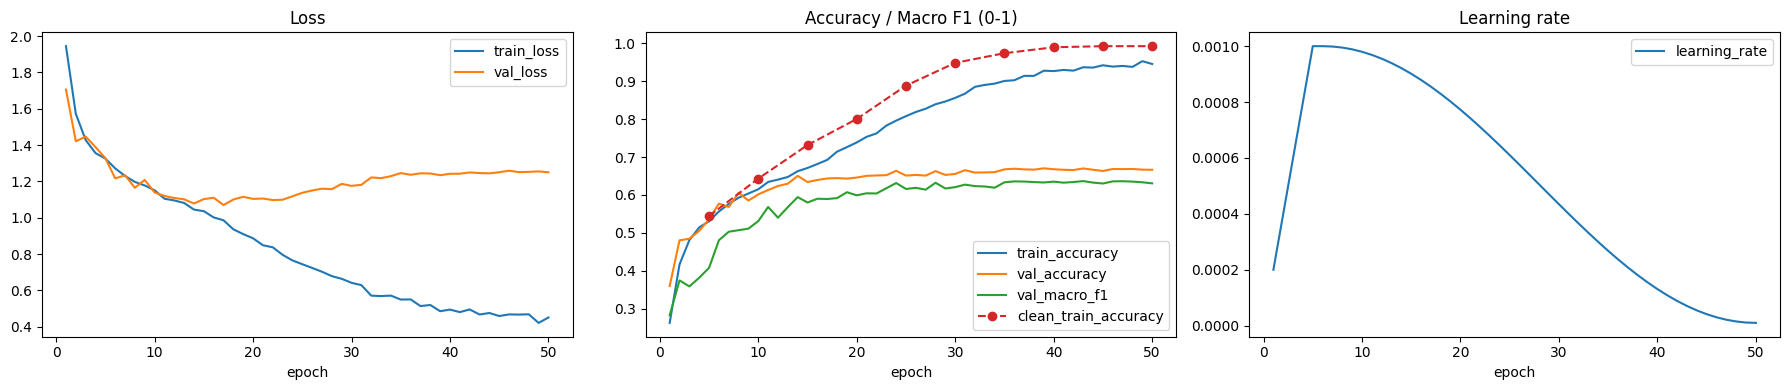

Evaluate:   0%|          | 0/45 [00:00<?, ?it/s]

Best validation: {
  "loss": 1.2339822404353886,
  "accuracy": 0.6701497735980495,
  "macro_f1": 0.6328007882069463
}
              precision    recall  f1-score   support

       angry     0.6283    0.6015    0.6146       399
     disgust     0.5278    0.4318    0.4750        44
        fear     0.5564    0.5415    0.5488       410
       happy     0.8407    0.8698    0.8550       722
     neutral     0.5860    0.6250    0.6049       496
         sad     0.5486    0.5259    0.5370       483
    surprise     0.7968    0.7918    0.7943       317

    accuracy                         0.6701      2871
   macro avg     0.6407    0.6268    0.6328      2871
weighted avg     0.6678    0.6701    0.6686      2871



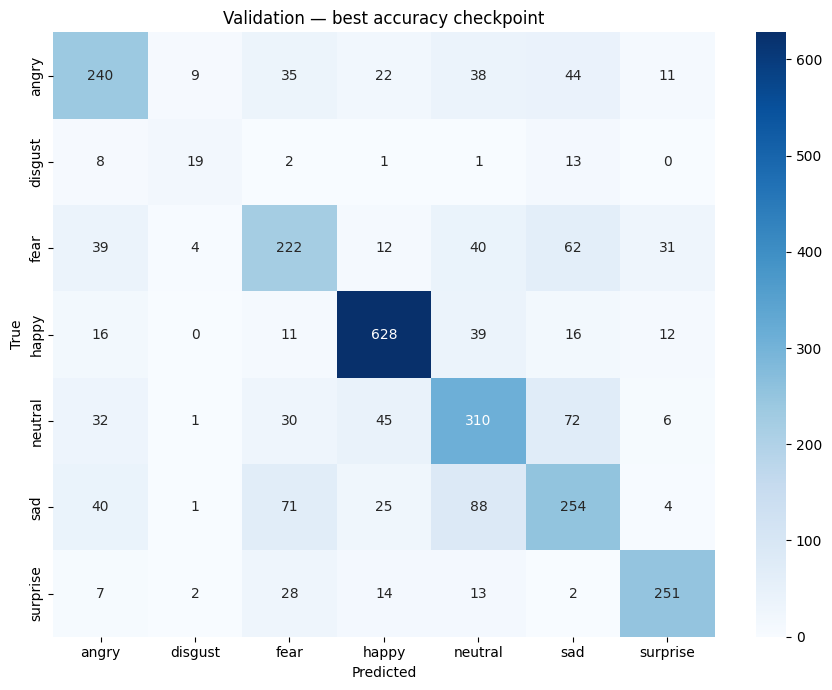

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
history.plot(x='epoch', y=['train_loss', 'val_loss'], ax=axes[0], title='Loss')
history.plot(x='epoch', y=['train_accuracy', 'val_accuracy', 'val_macro_f1'],
             ax=axes[1], title='Accuracy / Macro F1 (0-1)')
clean = history.dropna(subset=['clean_train_accuracy'])
axes[1].plot(clean['epoch'], clean['clean_train_accuracy'], 'o--', label='clean_train_accuracy')
axes[1].legend()
history.plot(x='epoch', y='learning_rate', ax=axes[2], title='Learning rate')
fig.tight_layout()
fig.savefig(RUN_DIR / 'training_history.png', dpi=150)
plt.show()

metadata = json.loads((RUN_DIR / 'training.json').read_text(encoding='utf-8'))
validation_model = load_trained_model(RUN_DIR / metadata['checkpoint_file'], DEVICE)
validation_result = evaluate(validation_model, loaders['val'], DEVICE,
                             build_criterion(CFG), CFG['use_amp'] and DEVICE.type == 'cuda')
print('Best validation:', json.dumps(scalar_metrics(validation_result), indent=2))
validation_report = classification_report(
    validation_result['targets'], validation_result['predictions'],
    labels=list(range(len(CLASS_NAMES))), target_names=list(CLASS_NAMES),
    digits=4, zero_division=0,
)
print(validation_report)
(RUN_DIR / 'validation_report.txt').write_text(validation_report, encoding='utf-8')
(RUN_DIR / 'validation_metrics.json').write_text(
    json.dumps(scalar_metrics(validation_result), indent=2), encoding='utf-8',
)
val_matrix = confusion_matrix(validation_result['targets'], validation_result['predictions'],
                              labels=list(range(len(CLASS_NAMES))))
pd.DataFrame(val_matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(RUN_DIR / 'validation_confusion_matrix.csv')
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(val_matrix, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
ax.set(title='Validation — best accuracy checkpoint', xlabel='Predicted', ylabel='True')
fig.tight_layout()
fig.savefig(RUN_DIR / 'validation_confusion_matrix.png', dpi=150)
plt.show()
del validation_model

## 7. Test sau khi chốt cấu hình

`RUN_FINAL_TEST=True` cho phép Run All xuất kết quả cuối. Khi đang thử nhiều
preset/hyperparameter, đặt False để chỉ xem validation. Cell này nạp đúng
model, cấu hình và best weights đã lưu trong run trước khi mở `test/`.

Dataset thư mục `msambare/fer2013` có thể có 7.178 ảnh test, khác benchmark
PrivateTest 3.589 ảnh. Kiểm tra số lượng và nguồn split trước khi so paper.
Tập test này đã được tham khảo ở các lần phát triển trước nên không xem là
một bộ đánh giá chưa từng được tham khảo. Cần báo cáo chính xác điều kiện.

Test execution: {'strategy': 'single', 'device_ids': [0]}
Reading 7,178 images with 4 I/O threads; cache is reused across epochs.


Cache decoded images:   0%|          | 0/7178 [00:00<?, ?img/s]

Cached 7,178 images | RGB pixels 47.3 MiB
Giới hạn trên tính theo pixel RGB; đối tượng PIL/Python dùng thêm một phần RAM.


Evaluate:   0%|          | 0/113 [00:00<?, ?it/s]

Test images: 7178
Test accuracy: 65.78% | Test macro F1: 64.00%
              precision    recall  f1-score   support

       angry     0.5641    0.5971    0.5801       958
     disgust     0.6774    0.5676    0.6176       111
        fear     0.5183    0.4844    0.5008      1024
       happy     0.8527    0.8579    0.8553      1774
     neutral     0.5834    0.6326    0.6070      1233
         sad     0.5363    0.4980    0.5164      1247
    surprise     0.8010    0.8039    0.8024       831

    accuracy                         0.6578      7178
   macro avg     0.6476    0.6345    0.6400      7178
weighted avg     0.6565    0.6578    0.6567      7178



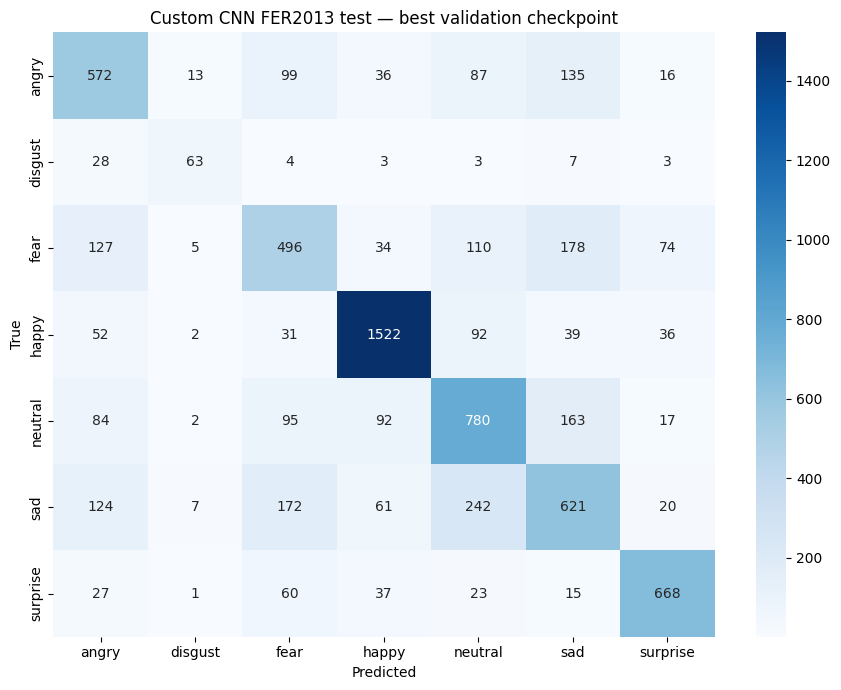

In [14]:
def evaluate_final_test(model, cfg, root, run_dir, device):
    metadata = json.loads((Path(run_dir) / 'training.json').read_text(encoding='utf-8'))
    cfg = metadata['config']
    model = load_trained_model(Path(run_dir) / metadata['checkpoint_file'], device)
    model = prepare_parallel_model(model, cfg, device)
    print('Test execution:', execution_info(model, device))
    test_dataset = datasets.ImageFolder(Path(root) / 'test', transform=build_transforms(cfg))
    check_classes(test_dataset)
    attach_image_cache(cfg, test_dataset)
    test_loader = DataLoader(
        test_dataset, batch_size=cfg['batch_size'], shuffle=False,
        num_workers=cfg['num_workers'], pin_memory=device.type == 'cuda',
        worker_init_fn=seed_worker,
    )
    result = evaluate(model, test_loader, device, build_criterion(cfg),
                      cfg['use_amp'] and device.type == 'cuda')
    metrics = {**scalar_metrics(result), 'test_size': len(test_dataset)}
    (Path(run_dir) / 'test_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
    print('Test images:', len(test_dataset))
    print(f'Test accuracy: {result["accuracy"]:.2%} | Test macro F1: {result["macro_f1"]:.2%}')
    report = classification_report(
        result['targets'], result['predictions'], labels=list(range(len(CLASS_NAMES))),
        target_names=list(CLASS_NAMES), digits=4, zero_division=0,
    )
    print(report)
    (Path(run_dir) / 'classification_report.txt').write_text(report, encoding='utf-8')
    pd.DataFrame({
        'path': [str(Path(path).relative_to(root)) for path, _ in test_dataset.samples],
        'target': result['targets'], 'prediction': result['predictions'],
    }).to_csv(Path(run_dir) / 'test_predictions.csv', index=False)
    matrix = confusion_matrix(result['targets'], result['predictions'], labels=list(range(len(CLASS_NAMES))))
    pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(Path(run_dir) / 'confusion_matrix.csv')
    return result, matrix



RUN_FINAL_TEST = True
if RUN_FINAL_TEST:
    test_result, matrix = evaluate_final_test(model, CFG, DATA_ROOT, RUN_DIR, DEVICE)
    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set(title='Custom CNN FER2013 test — best validation checkpoint', xlabel='Predicted', ylabel='True')
    fig.tight_layout()
    fig.savefig(RUN_DIR / 'test_confusion_matrix.png', dpi=150)
    plt.show()
else:
    print('Bỏ qua test: tiếp tục chọn cấu hình bằng validation.')

## 8. Lưu weights và dùng lại

Thư mục `Output:` đầu cell train trỏ đến run hiện tại, thường là
`/kaggle/working/fer2013_custom_cnn_fusion_<thời gian>`.

- `custom_cnn_fer2013_best_checkpoint.pth`: weights kèm kiến trúc, nhãn,
  chuẩn hóa một kênh, best epoch và validation metrics; nên tải file này.
- `custom_cnn_fer2013_best.pth`: raw state dict, cần biết cấu hình để tạo model.
- `training.json`, `model_config.json`, `best_validation.json`, `history.csv`.
- `split_manifest.csv`, report/confusion matrix validation và test.

Sau khi chạy các cell định nghĩa model, nạp lại không cần Internet:

```python
restored = load_trained_model(RUN_DIR / 'custom_cnn_fer2013_best_checkpoint.pth', DEVICE)
```

Model này cần ảnh **grayscale một kênh, 48×48, Normalize(0.5, 0.5)**.
Không dùng weights này trực tiếp với ứng dụng CCT trong `src/fer` đang nhận
3×224×224; cần tích hợp kiến trúc và tiền xử lý mới khi triển khai ứng dụng.

So `deep_only` với `fusion` để đánh giá nhánh hợp nhất, rồi `fusion` với
`fusion_cbam` để đánh giá attention, giữ seed/split và ngân sách train.
Sau khi chọn cấu hình, thử vài seed train và báo cáo trung bình/độ dao động
validation thay vì chỉ lấy run tốt nhất. Ghi cả accuracy, Macro F1, số tham
số, thời gian train và thiết bị. Không giả định model nhỏ hơn luôn chính xác hơn.